# Chapitre 14 - Exercices 14.1 à 14.6

Pondération des distances, algorithme EM et K-means, règles d'association généralisées par
arbres et PRIM, cartes auto-organisatrices.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch14_non_supervise as ns
set_style()

## Exercice 14.1 : Poids dans une distance euclidienne

**Énoncé.** On définit la distance euclidienne pondérée, de poids $w_l > 0$,

$$d_e^{(w)}(x_i, x_{i'}) = \frac{\sum_{l=1}^p w_l (x_{il} - x_{i'l})^2}{\sum_{l=1}^p w_l}.$$

Montrer que $d_e^{(w)}(x_i, x_{i'}) = d_e(z_i, z_{i'}) = \sum_{l=1}^p (z_{il} - z_{i'l})^2$
(éq. (14.112)) avec $z_{il} = x_{il}\,\big(w_l / \sum_{l'} w_{l'}\big)^{1/2}$ (éq. (14.113)) :
la distance pondérée sur $x$ est la distance usuelle sur des variables $z$ remises à l'échelle.

### Solution

Notons $W = \sum_{l'} w_{l'} > 0$ et $c_l = (w_l/W)^{1/2}$, de sorte que $z_{il} = c_l\, x_{il}$.
Pour chaque coordonnée $l$, par linéarité,

$$z_{il} - z_{i'l} = c_l\,(x_{il} - x_{i'l}) \quad\Longrightarrow\quad
(z_{il} - z_{i'l})^2 = c_l^2 (x_{il} - x_{i'l})^2 = \frac{w_l}{W}(x_{il} - x_{i'l})^2 .$$

En sommant sur $l$ :
$\sum_l (z_{il} - z_{i'l})^2 = \frac{1}{W}\sum_l w_l (x_{il} - x_{i'l})^2 = d_e^{(w)}(x_i, x_{i'})$.
$\square$

> **Conséquence pratique.** Tout algorithme fondé sur la distance euclidienne (K-means,
> classification hiérarchique…) appliqué avec des poids $w_l$ équivaut à l'algorithme
> **non pondéré** appliqué aux variables $z_l = c_l x_l$ : pondérer, c'est changer d'échelle.
> Par exemple les poids $w_l = 1/(2\,\mathrm{var}_l)$ correspondent à la standardisation.

### Vérification numérique

In [2]:
rng = np.random.RandomState(0)
X = rng.normal(size=(6, 4))
w = np.array([1.0, 4.0, 0.5, 2.0])
d_w = (w * (X[:, None, :] - X[None, :, :]) ** 2).sum(-1) / w.sum()
Z = X * np.sqrt(w / w.sum())
d_z = ns.distances_carrees(Z)
print("écart maximal entre les deux matrices : %.2e" % np.abs(d_w - d_z).max())

écart maximal entre les deux matrices : 1.78e-15


Les K-means « pondérés » (affectation selon $d_e^{(w)}$, centres = moyennes) donnent donc la
même partition que les K-means ordinaires sur $Z$ :

In [3]:
X2 = np.vstack([rng.normal(m, 1, size=(40, 2)) for m in ((0, 0), (0, 4), (6, 2))])
w2 = np.array([1.0, 9.0])
Z2 = X2 * np.sqrt(w2 / w2.sum())
lab_z, C_z, _ = ns.kmeans(Z2, 3, rng=np.random.RandomState(0))
C = C_z / np.sqrt(w2 / w2.sum())          # centres ramenés dans l'échelle de x
lab_w = ((w2 * (X2[:, None, :] - C[None]) ** 2).sum(-1)).argmin(1)
print("Partitions identiques :", np.array_equal(lab_z, lab_w))

Partitions identiques : True


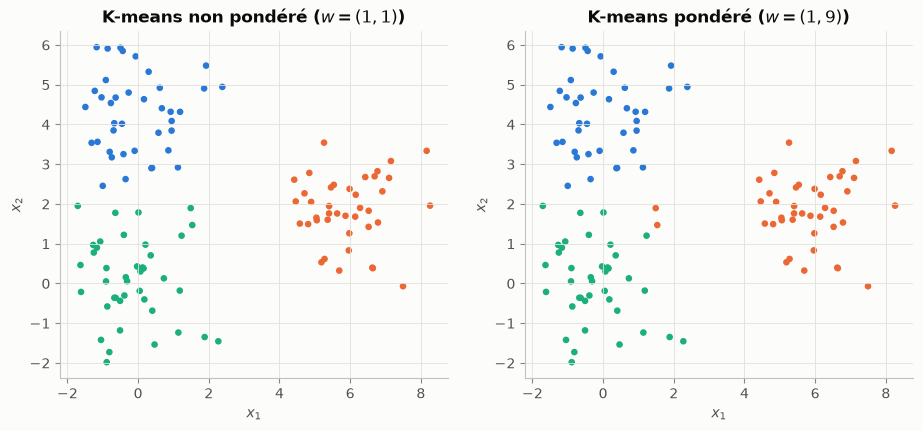

In [4]:
lab_x = ns.kmeans(X2, 3, rng=np.random.RandomState(0))[0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, lab, titre in ((axes[0], lab_x, "K-means non pondéré ($w = (1, 1)$)"),
                       (axes[1], lab_w, "K-means pondéré ($w = (1, 9)$)")):
    ax.scatter(*X2.T, c=[COLORS[k] for k in lab], s=14)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title(titre)
plt.show()

Le poids 9 sur $x_2$ revient à étirer l'axe vertical d'un facteur 3 : la partition change.

> **À retenir.** Pondérer la distance euclidienne équivaut à multiplier chaque variable par la
> racine de son poids normalisé ; le choix des poids est un choix d'échelle des variables.

## Exercice 14.2 : Algorithme EM pour un mélange gaussien isotrope et K-means

**Énoncé.** On considère le mélange $g(x) = \sum_{k=1}^K \pi_k g_k(x)$ (14.114) avec
$g_k = \mathcal{N}(\mu_k, \sigma^2 \mathbf{I})$ ($\mathbf{I}$ : identité $p \times p$), $\pi_k \ge 0$,
$\sum_k \pi_k = 1$, les paramètres $\{\mu_k, \pi_k\}$ et $\sigma^2$ étant inconnus. On observe
$x_1, \dots, x_N$ i.i.d. de densité $g$.

1. Écrire la log-vraisemblance.
2. Dériver un algorithme EM pour l'estimateur du maximum de vraisemblance.
3. Montrer que si $\sigma$ est connu et tend vers 0, cet algorithme coïncide en un sens avec les
   K-means.

### Rappels : densité gaussienne isotrope

La densité de $\mathcal{N}(\mu, \sigma^2\mathbf{I})$ dans $\mathbb{R}^p$ est

$$\phi_\sigma(x; \mu) = (2\pi\sigma^2)^{-p/2} \exp\Big(-\frac{\|x - \mu\|^2}{2\sigma^2}\Big).$$

### 1. Log-vraisemblance

Par indépendance, la vraisemblance est le produit des densités, d'où

$$\ell(\theta) = \sum_{i=1}^N \log g(x_i) = \sum_{i=1}^N \log\Big(\sum_{k=1}^K \pi_k\,
\phi_\sigma(x_i; \mu_k)\Big), \qquad \theta = (\pi_k, \mu_k, \sigma^2)_k .$$

Le logarithme d'une **somme** empêche de résoudre directement les équations $\nabla\ell = 0$ :
c'est la motivation de l'algorithme EM.

### 2. L'algorithme EM

**Idée (section 8.5 du livre).** On imagine des variables **latentes** $\Delta_i \in \{1, \dots,
K\}$ indiquant de quelle composante provient $x_i$ : $\Pr(\Delta_i = k) = \pi_k$ et, sachant
$\Delta_i = k$, $x_i \sim \mathcal{N}(\mu_k, \sigma^2\mathbf{I})$. Si les $\Delta_i$ étaient connus, la
log-vraisemblance **complète** serait facile à maximiser :

$$\ell_0(\theta) = \sum_{i=1}^N \sum_{k=1}^K \mathbb{1}\{\Delta_i = k\}\Big[\log \pi_k
 - \frac{p}{2}\log(2\pi\sigma^2) - \frac{\|x_i - \mu_k\|^2}{2\sigma^2}\Big].$$

EM alterne : (E) remplacer les indicatrices inconnues par leur **espérance conditionnelle**
sachant les données et les paramètres courants ; (M) maximiser l'expression obtenue.
On admet ici le résultat de la section 8.5 : chaque itération fait **croître** $\ell(\theta)$.

**Étape E.** Par la formule de Bayes, la « responsabilité » de la composante $k$ pour $x_i$ est

$$\gamma_{ik} = \mathbb{E}\big[\mathbb{1}\{\Delta_i = k\}\mid x_i, \hat\theta\big]
 = \Pr(\Delta_i = k \mid x_i) = \frac{\hat\pi_k\, \phi_{\hat\sigma}(x_i; \hat\mu_k)}
 {\sum_{l=1}^K \hat\pi_l\, \phi_{\hat\sigma}(x_i; \hat\mu_l)} .$$

Comme toutes les composantes ont la même variance, le facteur $(2\pi\sigma^2)^{-p/2}$ se
simplifie : $\gamma_{ik} \propto \hat\pi_k \exp(-\|x_i - \hat\mu_k\|^2/(2\hat\sigma^2))$.

**Étape M.** On maximise
$Q(\theta) = \sum_{i,k} \gamma_{ik}\big[\log\pi_k - \frac{p}{2}\log(2\pi\sigma^2) -
\frac{\|x_i - \mu_k\|^2}{2\sigma^2}\big]$. Notons $N_k = \sum_i \gamma_{ik}$ (effectif « doux »).

* **Moyennes.** $\nabla_{\mu_k} Q = \frac{1}{\sigma^2}\sum_i \gamma_{ik}(x_i - \mu_k) = 0$, d'où
  $\hat\mu_k = \frac{1}{N_k}\sum_i \gamma_{ik} x_i$ (moyenne pondérée par les responsabilités).
* **Proportions.** On maximise $\sum_k N_k \log \pi_k$ sous $\sum_k \pi_k = 1$ ; avec un
  multiplicateur de Lagrange $\nu$ : $N_k/\pi_k = \nu$, et $\sum_k \pi_k = 1$ donne
  $\nu = \sum_k N_k = N$, d'où $\hat\pi_k = N_k / N$.
* **Variance.** $\partial Q/\partial\sigma^2 = -\frac{Np}{2\sigma^2} + \frac{1}{2\sigma^4}
  \sum_{i,k}\gamma_{ik}\|x_i - \mu_k\|^2 = 0$ (car $\sum_{i,k}\gamma_{ik} = N$), d'où
  $\hat\sigma^2 = \frac{1}{Np}\sum_{i,k}\gamma_{ik}\|x_i - \hat\mu_k\|^2$.

**Algorithme.** Initialiser $\hat\mu_k$ (par exemple $K$ observations au hasard), $\hat\pi_k =
1/K$, $\hat\sigma^2$ = variance globale ; puis répéter étape E et étape M jusqu'à stabilisation de
$\ell$. C'est la fonction `ns.em_melange_isotrope`.

### 3. Limite $\sigma \to 0$ : les K-means

Fixons $\sigma$ (connu) et supposons, pour simplifier, $\pi_k > 0$. Pour une observation $x_i$,
soit $k^*$ l'indice du centre le plus proche, supposé unique : $\|x_i - \mu_{k^*}\|^2 <
\|x_i - \mu_k\|^2$ pour $k \ne k^*$. En divisant numérateur et dénominateur par le terme de $k^*$,

$$\gamma_{ik} = \frac{(\pi_k/\pi_{k^*}) \exp\big(-(\|x_i - \mu_k\|^2 - \|x_i - \mu_{k^*}\|^2)/(2\sigma^2)\big)}
{1 + \sum_{l \ne k^*} (\pi_l/\pi_{k^*}) \exp\big(-(\|x_i - \mu_l\|^2 - \|x_i - \mu_{k^*}\|^2)/(2\sigma^2)\big)} .$$

Les différences de distances au carré sont strictement positives, donc chaque exponentielle
tend vers 0 quand $\sigma \to 0$ : $\gamma_{ik^*} \to 1$ et $\gamma_{ik} \to 0$ pour $k \ne k^*$.

À la limite :

* l'**étape E** devient l'affectation de chaque point au centre le plus proche, exactement
  l'étape (14.34) des K-means ;
* l'**étape M** pour les centres devient $\hat\mu_k = $ moyenne des points affectés au groupe $k$,
  exactement l'étape (14.32).

En ce sens, EM avec $\sigma \to 0$ coïncide avec les K-means : les K-means sont un EM « dur ».
Les proportions $\pi_k$ n'interviennent plus dans l'affectation (leur influence, en
$\log(\pi_k/\pi_{k^*})$, est écrasée par le terme en $1/\sigma^2$).

### Vérification numérique

Données en trois groupes ; on lance EM avec $\sigma$ libre, puis avec $\sigma$ fixé de plus en plus
petit, à partir des mêmes centres initiaux, et on compare aux K-means partant des mêmes centres.

In [5]:
rng = np.random.RandomState(0)
Xe = np.vstack([rng.normal(m, 0.9, size=(60, 2)) for m in ((0, 0), (3, 0.5), (1.5, 3))])
mu0 = Xe[rng.choice(len(Xe), 3, replace=False)]
em_libre = ns.em_melange_isotrope(Xe, 3, mu_init=mu0, n_iter=500)
print("sigma^2 estimé : %.3f ; proportions : %s" % (em_libre["sigma2"], em_libre["pi"].round(3)))

sigma^2 estimé : 0.816 ; proportions : [0.34  0.374 0.286]


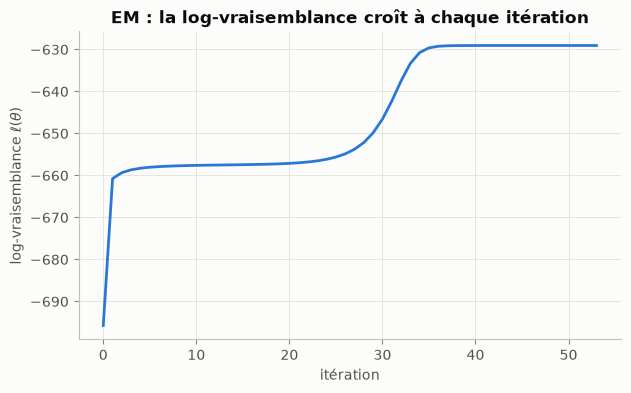

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(em_libre["loglik"], color=BLUE)
ax.set_xlabel("itération")
ax.set_ylabel("log-vraisemblance $\\ell(\\theta)$")
ax.set_title("EM : la log-vraisemblance croît à chaque itération")
plt.show()

In [7]:
lab_km, C_km, _ = ns.kmeans(Xe, 3, centres_init=mu0)
for s in (1.0, 0.5, 0.2, 0.05):
    em = ns.em_melange_isotrope(Xe, 3, sigma2=s ** 2, mu_init=mu0, n_iter=500)
    durete = em["resp"].max(1).mean()
    ecart = np.abs(np.sort(em["mu"], 0) - np.sort(C_km, 0)).max()
    print("sigma = %.2f : max_k gamma_ik moyen = %.3f, |mu_EM - centres K-means| max = %.3f"
          % (s, durete, ecart))

sigma = 1.00 : max_k gamma_ik moyen = 0.885, |mu_EM - centres K-means| max = 0.165
sigma = 0.50 : max_k gamma_ik moyen = 0.981, |mu_EM - centres K-means| max = 0.034
sigma = 0.20 : max_k gamma_ik moyen = 0.998, |mu_EM - centres K-means| max = 0.008
sigma = 0.05 : max_k gamma_ik moyen = 1.000, |mu_EM - centres K-means| max = 0.000


Quand $\sigma$ diminue, les responsabilités deviennent 0 ou 1 et les centres d'EM rejoignent
ceux des K-means. Visualisons la responsabilité du groupe le plus probable.

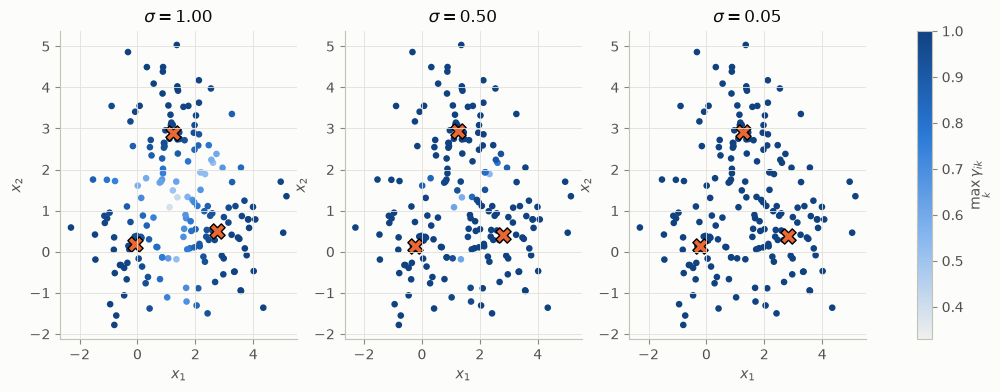

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, s in zip(axes, (1.0, 0.5, 0.05)):
    em = ns.em_melange_isotrope(Xe, 3, sigma2=s ** 2, mu_init=mu0, n_iter=500)
    sc = ax.scatter(*Xe.T, c=em["resp"].max(1), cmap=SEQ, vmin=0.33, vmax=1, s=14)
    ax.scatter(*em["mu"].T, marker="X", s=120, color=ORANGE, edgecolor="k")
    ax.set_title("$\\sigma = %.2f$" % s)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
plt.colorbar(sc, ax=axes, label="$\\max_k \\gamma_{ik}$")
plt.show()

> **À retenir.** Pour un mélange gaussien isotrope, EM alterne responsabilités (étape E) et
> moyennes/proportions/variance pondérées (étape M). Quand $\sigma \to 0$, les responsabilités
> deviennent des affectations dures au centre le plus proche : on retrouve exactement les deux
> étapes des K-means.

## Exercice 14.3 : CART et PRIM avec la référence « produit des marginales »

**Énoncé.** La section 14.2.6 propose d'utiliser CART ou PRIM pour construire des règles
d'association généralisées. Montrer qu'un problème survient avec ces deux méthodes lorsque les
données de référence sont tirées de la loi **produit des marginales**, c'est-à-dire en permutant
aléatoirement les valeurs de chaque variable. Proposer des moyens de contourner ce problème.

### Le problème

Notons $\mathbf{X}$ ($N \times p$) les données (classe $Y = 1$) et $\mathbf{X}_0$ l'échantillon de
référence (classe $Y = 0$) obtenu en permutant **indépendamment** chaque colonne de $\mathbf{X}$
($N_0 = N$). Chaque colonne de $\mathbf{X}_0$ contient **exactement les mêmes valeurs** que la
colonne correspondante de $\mathbf{X}$, dans un autre ordre.

**Propriété.** Pour toute variable $j$ et tout ensemble de valeurs $s$, les nombres d'observations
vérifiant $X_j \in s$ sont égaux dans les deux échantillons :
$\#\{i : x_{ij} \in s\} = \#\{i : x^0_{ij} \in s\}$. En effet, une permutation ne fait que
réordonner les valeurs de la colonne.

**Conséquence pour CART.** Toute coupure de la racine est de la forme $\{X_j \in s\}$ contre
$\{X_j \notin s\}$. Dans chaque nœud fils, il y a autant d'observations de chaque classe, donc
la proportion de la classe 1 vaut exactement $1/2$, comme à la racine : **l'impureté (Gini,
entropie ou erreur) ne diminue pas**, quelle que soit la coupure. La recherche gloutonne n'a
aucun critère pour choisir la première coupure : elle s'arrête (si l'on exige un gain
strictement positif) ou choisit arbitrairement.

**Conséquence pour PRIM.** Le premier « épluchage » retire une tranche $\{X_j \in s\}$ pour une
seule variable : la boîte restante est $\{X_j \notin s\}$, de moyenne exactement $1/2$. Aucun
épluchage n'améliore la moyenne de la boîte : le premier pas est lui aussi aveugle.

> **Intuition.** Par construction, la référence a les mêmes lois marginales que les données ;
> seule la **dépendance** entre variables les distingue. Or une règle qui ne porte que sur une
> variable ne « voit » que la loi marginale. Il faut au moins **deux** variables à la fois pour
> détecter une différence, alors que CART et PRIM procèdent une variable à la fois.

### Vérification numérique sur les données `marketing`

In [9]:
mk = datasets.load_marketing().dropna().astype(int)
Xm = mk.to_numpy(float)
N, p = Xm.shape
X0 = ns.echantillon_reference(Xm, "permutation", np.random.RandomState(0))
XX = np.vstack([Xm, X0])
yy = np.r_[np.ones(N), np.zeros(N)]
gains = []
for j in range(p):
    for s in np.unique(Xm[:, j])[:-1]:
        g = XX[:, j] <= s
        gains.append(abs(yy[g].mean() - 0.5) + abs(yy[~g].mean() - 0.5))
print("Coupures univariées testées :", len(gains), "; écart maximal à 1/2 dans les fils : %.1e" % max(gains))

Coupures univariées testées : 70 ; écart maximal à 1/2 dans les fils : 0.0e+00


Un arbre de profondeur 1 de scikit-learn (utilisé ici et dans l'exercice suivant, CART étant
l'objet du chapitre 9 et lourd à recoder) le confirme : l'impureté de Gini des fils est
exactement celle de la racine.

In [10]:
souche = DecisionTreeClassifier(max_depth=1).fit(XX, yy).tree_
print("Gini racine, fils gauche, fils droit :", souche.impurity.round(4))
print("Variable choisie (arbitrairement) :", mk.columns[souche.feature[0]])

Gini racine, fils gauche, fils droit : [0.5 0.5 0.5]
Variable choisie (arbitrairement) : Dual_Income


Pour PRIM, la moyenne après le premier épluchage reste égale à 1/2 :

In [11]:
cat_idx = [list(mk.columns).index(c) for c in ns.CATEGORIELLES_MARKETING]
prim0 = ns.prim_peeling(XX, yy, cat_idx, alpha=0.05, support_min=0.1)
print("Moyennes de y le long de l'épluchage :", prim0["moyennes"][:6].round(3))

Moyennes de y le long de l'épluchage : [0.5   0.5   0.542 0.669 0.741 0.781]


Le premier pas (0,5 → 0,5) est arbitraire ; ensuite, une fois une variable restreinte, les
marginales des autres variables **dans la boîte** diffèrent entre données et référence, et la
recherche redevient informative. Mais tout le résultat dépend d'un premier choix fait au hasard.

### Remèdes

1. **Anticipation (« lookahead »)** : choisir la première coupure (ou le premier épluchage) en
   regardant le meilleur gain obtenu **après deux étapes**, c'est-à-dire en évaluant des
   conjonctions de deux conditions $\{X_j \in s\} \cap \{X_k \in s'\}$. Le coût passe de $O(p)$ à
   $O(p^2)$ candidats pour ce premier pas seulement.
2. **Coupures multivariées** pour le premier pas (par exemple sur des paires de variables, ou des
   combinaisons linéaires).
3. **Changer de référence** : une référence uniforme, ou un mélange de la loi produit et de
   l'uniforme, rompt l'égalité exacte des marges (au prix d'une interprétation différente du
   rapport $g/g_0$).
4. **Méthodes non gloutonnes** : forêts aléatoires ou boosting d'arbres de profondeur ≥ 2, qui
   modélisent directement les interactions ; on cherche ensuite les régions de forte valeur de
   $\hat\mu(x)$.

Implémentons le remède 1 pour PRIM : on évalue toutes les paires d'épluchages élémentaires
(une tranche de 5 % ou une modalité retirée, sur deux variables distinctes), on garde la
meilleure, puis on poursuit l'épluchage ordinaire à partir de cette boîte.

In [12]:
def epluchages(X, dedans, cat, alpha=0.05):
    """Liste des masques obtenus par un épluchage élémentaire de la boîte 'dedans'."""
    out = []
    for j in range(X.shape[1]):
        xj = X[dedans, j]
        if j in cat:
            for m in np.unique(xj):
                out.append((j, dedans & (X[:, j] != m)))
        else:
            lo, hi = np.quantile(xj, [alpha, 1 - alpha])
            out += [(j, dedans & (X[:, j] > lo)), (j, dedans & (X[:, j] < hi))]
    return [(j, m) for j, m in out if 0 < m.sum() < dedans.sum()]


tous = np.ones(len(XX), bool)
premiers = epluchages(XX, tous, set(cat_idx))
meilleur = (0, None)
for j1, m1 in premiers:
    for j2, m2 in premiers:
        if j2 > j1:
            m = m1 & m2
            if m.sum() > 0.5 * len(XX) and yy[m].mean() > meilleur[0]:
                meilleur = (yy[m].mean(), (j1, j2), m)
print("Meilleure paire de premiers épluchages : %s et %s, moyenne %.3f"
      % (mk.columns[meilleur[1][0]], mk.columns[meilleur[1][1]], meilleur[0]))

Meilleure paire de premiers épluchages : Marital et Dual_Income, moyenne 0.567


La paire d'épluchages fait déjà passer la moyenne au-dessus de 1/2, alors que chaque épluchage
isolé la laisse à 1/2 : l'anticipation d'un pas suffit à rendre le premier choix informatif. On
poursuit ensuite PRIM normalement à partir de cette boîte.

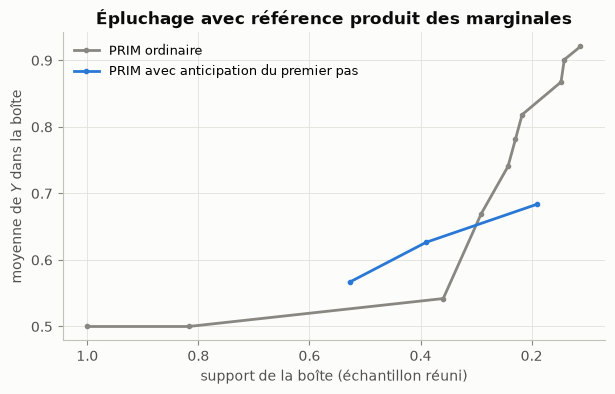

In [13]:
sous = meilleur[2]
suite = ns.prim_peeling(XX[sous], yy[sous], cat_idx, alpha=0.05, support_min=0.1 * len(XX) / sous.sum())
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(prim0["supports"], prim0["moyennes"], "o-", ms=3, color=GRAY, label="PRIM ordinaire")
ax.plot(suite["supports"] * sous.mean(), suite["moyennes"], "o-", ms=3, color=BLUE,
        label="PRIM avec anticipation du premier pas")
ax.invert_xaxis()
ax.set_xlabel("support de la boîte (échantillon réuni)")
ax.set_ylabel("moyenne de $Y$ dans la boîte")
ax.set_title("Épluchage avec référence produit des marginales")
ax.legend()
plt.show()

> **À retenir.** Avec une référence « colonnes permutées », données et référence ont exactement
> les mêmes marges : aucune règle portant sur une seule variable ne les distingue, et le premier
> pas de CART ou de PRIM est aveugle. On y remédie en anticipant (conditions sur des paires de
> variables), en utilisant des coupures multivariées ou une autre référence.

## Exercice 14.4 : Règles généralisées par arbre de classification sur les données démographiques

**Énoncé.** Classer les données démographiques du tableau 14.1 à l'aide d'un arbre de
classification : générer un échantillon de référence de même taille en permutant les valeurs de
chaque variable, ajuster un arbre (données = classe 1, référence = classe 0) et décrire les
feuilles de plus forte probabilité estimée de la classe 1. Comparer aux résultats de PRIM
donnés près du tableau 14.1 et aux K-means appliqués aux mêmes données.

### Mise en œuvre

On réutilise l'échantillon réuni de l'exercice 14.3 (6876 + 6876 observations). On ajuste un arbre
CART (scikit-learn, critère de Gini) avec au plus 25 feuilles d'au moins 150 observations.

> **Remarques.** (i) Comme montré dans l'exercice 14.3, la coupure de la racine est arbitraire ;
> les coupures suivantes sont informatives. (ii) scikit-learn traite les codes des variables
> catégorielles comme ordonnés : une coupure « Status ≤ 1,5 » sépare la modalité 1 des autres,
> ce qui reste interprétable, mais toutes les partitions de modalités ne sont pas accessibles.

In [14]:
arbre = DecisionTreeClassifier(max_leaf_nodes=25, min_samples_leaf=150, random_state=0).fit(XX, yy)
T = arbre.tree_
feuilles = np.where(T.children_left == -1)[0]
proba = T.value[feuilles, 0, 1] / T.value[feuilles, 0].sum(1)
n_feuille = T.n_node_samples[feuilles]
print("Nombre de feuilles :", len(feuilles))

Nombre de feuilles : 25


Pour décrire une feuille, on remonte le chemin depuis la racine et on intersecte les conditions
variable par variable, puis on traduit les intervalles de codes en modalités.

In [15]:
parent = {}
for nd in range(T.node_count):
    for fils, cote in ((T.children_left[nd], "<="), (T.children_right[nd], ">")):
        if fils != -1:
            parent[fils] = (nd, cote)


def regle_feuille(f):
    bornes = {}
    while f in parent:
        nd, cote = parent[f]
        j, s = T.feature[nd], T.threshold[nd]
        lo, hi = bornes.get(j, (-np.inf, np.inf))
        bornes[j] = (lo, min(hi, s)) if cote == "<=" else (max(lo, s), hi)
        f = nd
    morceaux = []
    for j, (lo, hi) in sorted(bornes.items()):
        v = mk.columns[j]
        vals = [x for x in np.unique(Xm[:, j]) if lo < x <= hi]
        if v in ns.MODALITES_MARKETING and v not in ns.ORDINALES_MARKETING:
            morceaux.append("%s ∈ {%s}" % (v, ", ".join(ns.MODALITES_MARKETING[v][int(x)] for x in vals)))
        else:
            morceaux.append("%s ∈ [%g, %g]" % (v, min(vals), max(vals)))
    return morceaux


ordre_f = np.argsort(-proba)
for r in ordre_f[:5]:
    f = feuilles[r]
    support = T.value[f, 0, 1] / T.value[f, 0].sum() * n_feuille[r] / N
    print("Feuille %d : P(classe 1) = %.3f, support dans les données = %.1f %%"
          % (f, proba[r], 100 * support))
    for m in regle_feuille(f):
        print("     ", m)
    print()

Feuille 38 : P(classe 1) = 0.913, support dans les données = 20.3 %
      Income ∈ [6, 9]
      Marital ∈ {marié, en couple non marié, divorcé/séparé, veuf}
      Age ∈ [3, 7]
      Dual_Income ∈ {oui, non}
      Status ∈ {propriétaire}
      Home_Type ∈ {maison}

Feuille 20 : P(classe 1) = 0.898, support dans les données = 14.5 %
      Marital ∈ {célibataire}
      Age ∈ [1, 2]
      Status ∈ {vit en famille}
      Home_Type ∈ {maison}

Feuille 48 : P(classe 1) = 0.835, support dans les données = 17.1 %
      Marital ∈ {en couple non marié, divorcé/séparé, veuf, célibataire}
      Household ∈ [1, 2]
      Householdu18 ∈ [0, 0]
      Status ∈ {locataire}
      Home_Type ∈ {copropriété, appartement, mobile home, autre}

Feuille 33 : P(classe 1) = 0.750, support dans les données = 2.8 %
      Age ∈ [1, 2]
      Edu ∈ [1, 3]
      Status ∈ {vit en famille}
      Home_Type ∈ {copropriété, appartement, mobile home, autre}

Feuille 45 : P(classe 1) = 0.723, support dans les données = 2.9 %
 

Les codes ordinaux s'interprètent avec le tableau 14.1 : par exemple `Age ∈ [1, 2]` signifie
« moins de 25 ans », `Householdu18 ∈ [0, 0]` « aucun enfant ».

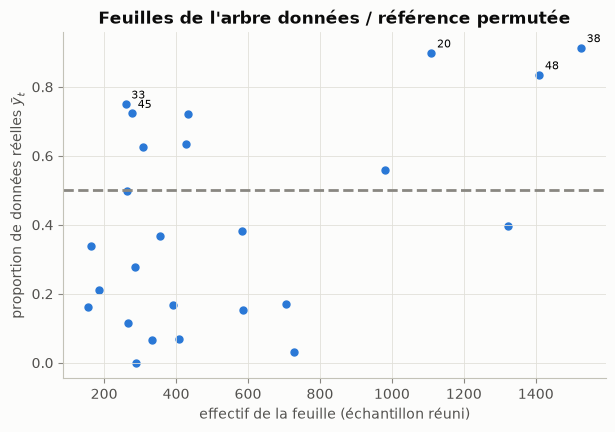

In [16]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(n_feuille, proba, color=BLUE, s=25)
for r in ordre_f[:5]:
    ax.annotate(str(feuilles[r]), (n_feuille[r], proba[r]), textcoords="offset points",
                xytext=(4, 4), fontsize=8)
ax.axhline(0.5, color=GRAY, ls="--")
ax.set_xlabel("effectif de la feuille (échantillon réuni)")
ax.set_ylabel("proportion de données réelles $\\bar y_t$")
ax.set_title("Feuilles de l'arbre données / référence permutée")
plt.show()

### Comparaison avec PRIM (livre)

Les ensembles d'items généralisés trouvés par PRIM dans le livre sont :

1. marié, propriétaire, logement ≠ appartement (support 24 %) ;
2. ≤ 24 ans, célibataire ou en couple non marié, profession hors {cadre, au foyer, retraité},
   locataire ou vivant en famille (support 24 %) ;
3. locataire, logement ≠ maison, foyer ≤ 2 personnes, sans enfant, profession hors {au foyer,
   étudiant, sans emploi}, revenu dans [20 k\$, 150 k\$] (support 15 %).

Les trois feuilles principales de l'arbre (supports 14 à 20 %) sont très proches de ces ensembles :

* « revenu ≥ 30 k\$, pas célibataire, 25 ans ou plus, propriétaire, maison » ↔ ensemble 1 de PRIM ;
* « célibataire, moins de 25 ans, vit en famille, maison » ↔ ensemble 2 ;
* « non marié, foyer de 1 ou 2 personnes, sans enfant, locataire, pas en maison » ↔ ensemble 3.

Ce sont des conjonctions de modalités **associées** (chacune rend les autres plus probables), et
non de modalités simplement fréquentes : c'est l'effet de la référence produit des marginales. Les
feuilles suivantes ont des supports bien plus faibles, car l'arbre partitionne tout l'espace au
lieu de chercher quelques grandes boîtes.

### Comparaison avec les K-means

On applique les K-means aux 50 indicatrices du cours 1 (codage disjonctif), avec $K = 4$, et on
décrit chaque groupe par les items dont la fréquence dans le groupe dépasse le plus la fréquence
globale (rapport de fréquences, analogue du lift).

In [17]:
Zd, noms, _ = ns.codage_disjonctif(mk, ns.ORDINALES_MARKETING, ns.CATEGORIELLES_MARKETING)
Zd = Zd.astype(float)
lab_k, C_k, _ = ns.kmeans(Zd, 4, n_init=10, rng=np.random.RandomState(0))
freq = Zd.mean(0)
for k in range(4):
    f_k = Zd[lab_k == k].mean(0)
    rapport = np.where(freq > 0.05, f_k / freq, 0)
    top = np.argsort(-rapport)[:5]
    print("Groupe %d (%.0f %% des données) :" % (k + 1, 100 * (lab_k == k).mean()),
          ", ".join("%s (%.0f %%)" % (noms[t], 100 * f_k[t]) for t in top))

Groupe 1 (18 % des données) : Occupation=5 (21 %), Dual_Income=2 (65 %), Householdu18>0 (96 %), Marital=1 (95 %), Household>3 (70 %)
Groupe 2 (34 % des données) : Home_Type=3 (68 %), Status=2 (94 %), Marital=2 (15 %), Marital=3 (15 %), Lived<5 (54 %)
Groupe 3 (23 % des données) : Status=3 (83 %), Occupation=6 (54 %), Marital=5 (93 %), Household>3 (67 %), Householdu18>0 (71 %)
Groupe 4 (25 % des données) : Occupation=8 (23 %), Status=1 (91 %), Age>3 (85 %), Dual_Income=3 (30 %), Income>6 (67 %)


Les groupes des K-means retrouvent des profils proches (jeunes vivant en famille, couples mariés
propriétaires, personnes seules locataires…), mais :

* ils forment une **partition** de toutes les observations (chaque personne est dans un groupe),
  alors que l'arbre et PRIM isolent seulement des régions de forte densité relative ;
* ils ne sont pas décrits par des **règles** simples : il faut les interpréter a posteriori ;
* la distance euclidienne sur les indicatrices traite toutes les modalités sur un pied d'égalité.

> **À retenir.** L'approche « données contre référence permutée » + arbre de classification
> produit des règles conjonctives lisibles décrivant des régions où les variables sont
> associées ; elle complète PRIM (une boîte à la fois, compromis support/moyenne contrôlé) et les
> K-means (partition complète sans règles explicites).

## Exercice 14.5 : SOM et K-means sur des données proches d'une sphère

**Énoncé.** Générer trois groupes de 30 points de $\mathbb{R}^3$ :
pour le groupe 1, $\theta_1 \sim U(-\pi/8, \pi/8)$, $\phi_1 \sim U(0, 2\pi)$ ; pour le groupe 2,
$\theta_2 \sim U(\pi/2 - \pi/4, \pi/2 + \pi/4)$, $\phi_2 \sim U(-\pi/4, \pi/4)$ ; pour le groupe 3,
$\theta_3 \sim U(\pi/2 - \pi/4, \pi/2 + \pi/4)$, $\phi_3 \sim U(\pi/2 - \pi/4, \pi/2 + \pi/4)$ ; puis
$x = \sin\theta\cos\phi + W_1$, $y = \sin\theta\sin\phi + W_2$, $z = \cos\theta + W_3$ avec des
$W$ gaussiens indépendants d'écart-type 0,6. Les données sont proches de la sphère, en trois
groupes centrés en $(0,0,1)$, $(1,0,0)$, $(0,1,0)$. Programmer une SOM avec les taux
d'apprentissage du texte, appliquer les K-means aux mêmes données et comparer aux résultats du
livre.

### Rappel : coordonnées sphériques

Le point $(\sin\theta\cos\phi, \sin\theta\sin\phi, \cos\theta)$ est sur la sphère unité ; $\theta$
est l'angle avec l'axe $z$ (colatitude), $\phi$ l'angle dans le plan $(x, y)$ (longitude).
Le groupe 1 ($\theta$ proche de 0) est autour du pôle nord $(0,0,1)$ ; les groupes 2 et 3
($\theta \approx \pi/2$, équateur) sont autour de $\phi = 0$, soit $(1,0,0)$, et de $\phi = \pi/2$,
soit $(0,1,0)$. Le groupe 1 a une étendue angulaire plus petite ($\pi/8$ contre $\pi/4$).

In [18]:
Xs, ys = ns.donnees_demi_sphere(n_par_classe=30, sd=0.6, rng=np.random.RandomState(0))
coul = np.array([COLORS[7], COLORS[5], COLORS[0]])[ys]
print("Moyennes par groupe :\n", np.array([Xs[ys == k].mean(0) for k in range(3)]).round(2))

Moyennes par groupe :
 [[-0.02  0.14  1.1 ]
 [ 0.71 -0.11  0.06]
 [ 0.08  0.55 -0.18]]


### SOM avec les réglages du texte

Grille $5 \times 5$, rayon initial $R = 2$, 40 passages (3600 itérations), $\alpha$ décroissant
linéairement de 1 à 0 et $r$ de 2 à 1 ; un nœud est voisin du gagnant si sa distance sur la grille
est strictement inférieure à $r$ (fonction `ns.som`).

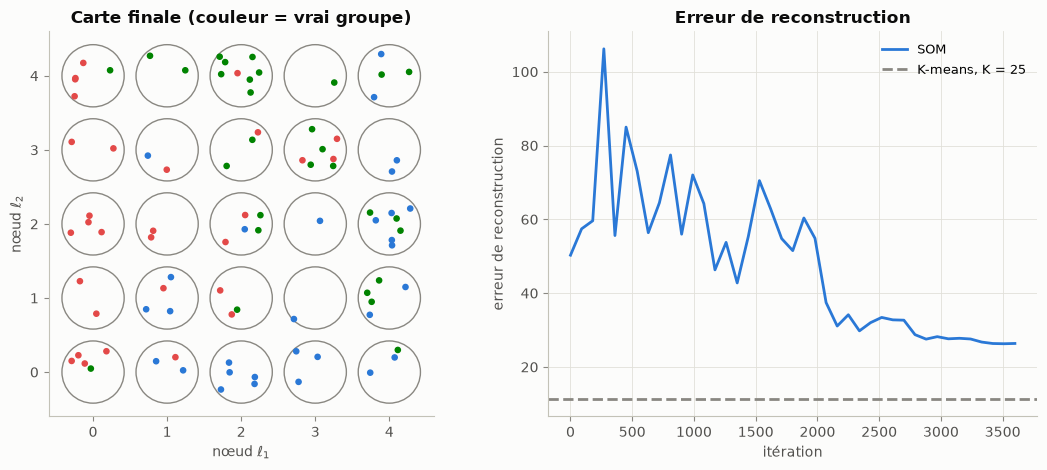

In [19]:
som = ns.som(Xs, 5, 5, n_iter=3600, R=2.0, rng=np.random.RandomState(0), suivi=90)
km25 = ns.kmeans(Xs, 25, n_init=20, rng=np.random.RandomState(0))
km3 = ns.kmeans(Xs, 3, n_init=20, rng=np.random.RandomState(0))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
jit = np.random.RandomState(1).uniform(-0.3, 0.3, size=(90, 2))
pos = som["grille"][som["labels"]] + jit
for (a, b) in som["grille"]:
    axes[0].add_patch(plt.Circle((a, b), 0.42, fill=False, color=GRAY))
axes[0].scatter(*pos.T, c=coul, s=14)
axes[0].set_xlim(-0.6, 4.6)
axes[0].set_ylim(-0.6, 4.6)
axes[0].set_aspect("equal")
axes[0].grid(False)
axes[0].set_title("Carte finale (couleur = vrai groupe)")
axes[0].set_xlabel("nœud $\\ell_1$")
axes[0].set_ylabel("nœud $\\ell_2$")
axes[1].plot(som["historique"][:, 0], som["historique"][:, 1], color=BLUE, label="SOM")
axes[1].axhline(km25[2], color=GRAY, ls="--", label="K-means, K = 25")
axes[1].set_xlabel("itération")
axes[1].set_ylabel("erreur de reconstruction")
axes[1].set_title("Erreur de reconstruction")
axes[1].legend()
plt.tight_layout()
plt.show()

Pour quantifier la séparation des groupes sur la carte, on regarde la **pureté** des nœuds :
proportion d'observations dont le nœud contient majoritairement leur groupe.

In [20]:
def purete(labels, y):
    tot = 0
    for k in np.unique(labels):
        tot += np.bincount(y[labels == k]).max()
    return tot / len(y)


print("Pureté des 25 nœuds de la SOM : %.2f" % purete(som["labels"], ys))
print("Pureté des 25 groupes des K-means : %.2f" % purete(km25[0], ys))
print("K-means K = 3 : Rand ajusté avec les vrais groupes = %.2f" % ns.indice_rand_ajuste(km3[0], ys))
print("Erreurs de reconstruction : SOM %.1f, K-means(25) %.1f" % (som["erreur"], km25[2]))

Pureté des 25 nœuds de la SOM : 0.76
Pureté des 25 groupes des K-means : 0.71
K-means K = 3 : Rand ajusté avec les vrais groupes = 0.21
Erreurs de reconstruction : SOM 26.4, K-means(25) 11.3


**Comparaison avec le livre.** Avec un bruit d'écart-type 0,6 (comparable au rayon de la
sphère !), les groupes se recouvrent beaucoup plus que sur la figure 14.15, qui semble obtenue
avec un bruit nettement plus faible. Les conclusions qualitatives restent :

* la SOM fait fortement baisser l'erreur de reconstruction, sans atteindre celle des K-means à 25
  centres (ici l'écart est plus marqué que sur la figure 14.18 du livre : la décroissance de $\alpha$
  jusqu'à 0 fige les prototypes avant qu'ils n'atteignent les moyennes de leurs cellules) ;
* les nœuds de la carte sont aussi purs (ici même un peu plus) que les groupes des K-means : la
  contrainte de grille ne coûte rien en séparation des groupes ;
* les K-means à 3 groupes ne retrouvent qu'imparfaitement les vrais groupes, faute de séparation.

Refaisons l'expérience avec un bruit plus faible (écart-type 0,2) pour nous rapprocher des figures
du livre.

In [21]:
Xs2, ys2 = ns.donnees_demi_sphere(n_par_classe=30, sd=0.2, rng=np.random.RandomState(0))
som2 = ns.som(Xs2, 5, 5, n_iter=3600, R=2.0, rng=np.random.RandomState(0))
km25b = ns.kmeans(Xs2, 25, n_init=20, rng=np.random.RandomState(0))
km3b = ns.kmeans(Xs2, 3, n_init=20, rng=np.random.RandomState(0))
print("sd = 0,2 : pureté SOM %.2f, pureté K-means(25) %.2f, Rand ajusté K-means(3) %.2f"
      % (purete(som2["labels"], ys2), purete(km25b[0], ys2), ns.indice_rand_ajuste(km3b[0], ys2)))

sd = 0,2 : pureté SOM 0.93, pureté K-means(25) 0.94, Rand ajusté K-means(3) 0.72


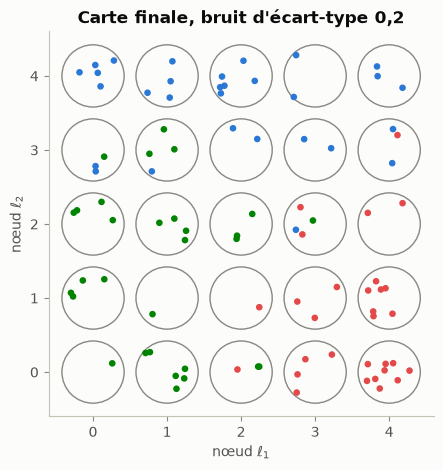

In [22]:
fig, ax = plt.subplots(figsize=(5.5, 5))
pos = som2["grille"][som2["labels"]] + jit
for (a, b) in som2["grille"]:
    ax.add_patch(plt.Circle((a, b), 0.42, fill=False, color=GRAY))
ax.scatter(*pos.T, c=np.array([COLORS[7], COLORS[5], COLORS[0]])[ys2], s=14)
ax.set_xlim(-0.6, 4.6)
ax.set_ylim(-0.6, 4.6)
ax.set_aspect("equal")
ax.grid(False)
ax.set_xlabel("nœud $\\ell_1$")
ax.set_ylabel("nœud $\\ell_2$")
ax.set_title("Carte finale, bruit d'écart-type 0,2")
plt.show()

Avec moins de bruit, la carte sépare nettement les trois groupes, comme sur la figure 14.16, et
les K-means à 3 groupes les retrouvent.

> **À retenir.** La SOM est un K-means contraint : son erreur de reconstruction est plus grande
> que celle des K-means au même nombre de prototypes, mais elle fournit en plus une carte 2D
> ordonnée. Comparer les deux erreurs permet de juger si la contrainte est raisonnable.

## Exercice 14.6 : K-means et SOM sur les échantillons NCI ; voisinage qui rétrécit

**Énoncé.** Programmer les K-means et une SOM dont les prototypes sont sur une grille
bidimensionnelle. Les appliquer aux colonnes (échantillons) des données de micro-puces, avec
$K = 2, 5, 10, 20$ centres. Montrer que lorsque le voisinage de la SOM devient de plus en plus
petit, la solution de la SOM se rapproche de celle des K-means.

### Mise en œuvre

Nos programmes sont `ns.kmeans` et `ns.som` / `ns.som_batch` (voir le module). Grilles :
$1\times2$, $1\times5$, $2\times5$, $4\times5$. Pour étudier l'effet de la taille du voisinage, on
utilise la SOM **batch** avec un noyau gaussien $h(d) = e^{-d^2/(2\tau^2)}$ de largeur $\tau$
**fixe** sur la grille : chaque prototype est la moyenne des observations affectées à tous les
nœuds, pondérées par $h(\|\ell_j - \ell_k\|)$ (14.48).

**Pourquoi la SOM tend vers les K-means.** Quand $\tau \to 0$, $h(0) = 1$ et $h(d) \to 0$ pour
$d \ge 1$ (les nœuds sont à distance au moins 1 les uns des autres) : chaque prototype devient la
moyenne des seules observations qui lui sont affectées, et l'itération batch de la SOM devient
exactement une itération des K-means (affectation au plus proche, puis moyenne). Si l'on part de
la même initialisation, la SOM converge vers le même point fixe que les K-means.

In [23]:
Xn, types = datasets.load_nci()
grilles = [(1, 2), (1, 5), (2, 5), (4, 5)]
taus = [3.0, 2.0, 1.0, 0.7, 0.5, 0.3, 0.1]
resultats = {}
for q1, q2 in grilles:
    K = q1 * q2
    init = ns.init_som_acp(Xn, q1, q2)
    km_meme_init = ns.kmeans(Xn, K, centres_init=init)
    ligne = []
    for tau in taus:
        o = ns.som_batch(Xn, q1, q2, n_iter=30, R=tau, r_final=tau, init=init, voisinage="gaussien")
        ligne.append((o["erreur"] / km_meme_init[2],
                      ns.indice_rand_ajuste(o["labels"], km_meme_init[0])))
    resultats[K] = np.array(ligne)
    print("K = %2d : erreur SOM / erreur K-means = %s" % (K, resultats[K][:, 0].round(3)))

K =  2 : erreur SOM / erreur K-means = [1.085 1.077 1.042 1.008 1.009 1.    1.   ]


K =  5 : erreur SOM / erreur K-means = [1.292 1.291 1.19  1.101 1.036 1.    1.   ]


K = 10 : erreur SOM / erreur K-means = [1.459 1.441 1.282 1.162 1.061 1.    1.   ]


K = 20 : erreur SOM / erreur K-means = [2.005 1.858 1.562 1.383 1.166 1.068 1.068]


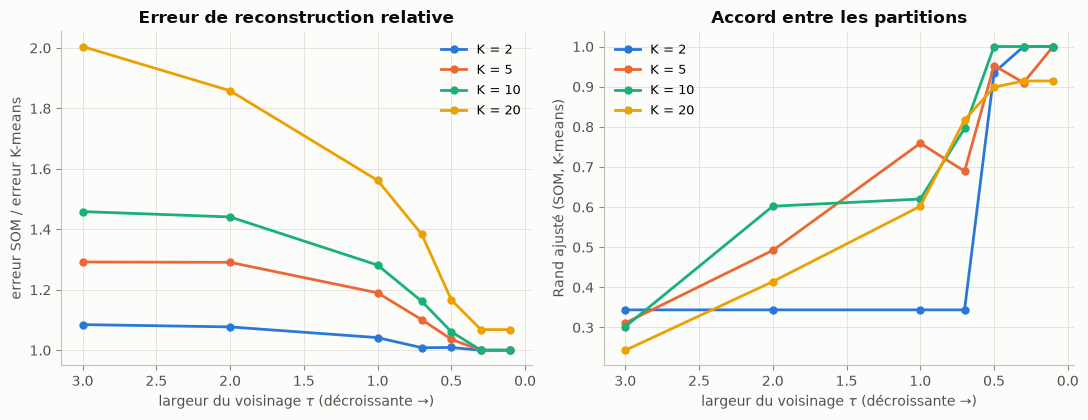

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for i, K in enumerate(resultats):
    axes[0].plot(taus, resultats[K][:, 0], "o-", color=COLORS[i], label="K = %d" % K)
    axes[1].plot(taus, resultats[K][:, 1], "o-", color=COLORS[i], label="K = %d" % K)
for ax in axes:
    ax.invert_xaxis()
    ax.set_xlabel("largeur du voisinage $\\tau$ (décroissante →)")
    ax.legend()
axes[0].set_ylabel("erreur SOM / erreur K-means")
axes[0].set_title("Erreur de reconstruction relative")
axes[1].set_ylabel("Rand ajusté (SOM, K-means)")
axes[1].set_title("Accord entre les partitions")
plt.tight_layout()
plt.show()

Quand le voisinage rétrécit, le rapport des erreurs tend vers 1 et l'indice de Rand ajusté vers 1 :
la SOM devient les K-means. Avec un grand voisinage, la SOM « tire » tous les prototypes vers la
moyenne générale et son erreur est bien plus grande, d'autant plus que $K$ est grand.

Pour $K = 20$ subsiste un petit écart (rapport ≈ 1,07) : 4 des 20 prototypes initiaux ne reçoivent
aucune observation. Les K-means les réinitialisent sur l'observation la plus mal représentée,
alors que la SOM les place (avec des poids minuscules) à la moyenne des cellules voisines ; les
deux algorithmes aboutissent alors à des points fixes légèrement différents.

Vérifions aussi avec la **SOM en ligne** (algorithme (14.46)) sur la grille $4 \times 5$ : avec un
rayon initial $R < 1$, seul le prototype gagnant est mis à jour à chaque pas (K-means en ligne).
On compare l'erreur à celle des K-means (meilleure de 10 initialisations) pour plusieurs $R$.

In [ ]:
km20 = ns.kmeans(Xn, 20, n_init=10, rng=np.random.RandomState(0))
for R in (4.0, 2.0, 1.5, 0.9):
    o = ns.som(Xn, 4, 5, n_iter=64 * 50, R=R, rng=np.random.RandomState(0))
    print("SOM en ligne, R = %.1f : erreur / erreur K-means = %.3f, Rand ajusté = %.2f"
          % (R, o["erreur"] / km20[2], ns.indice_rand_ajuste(o["labels"], km20[0])))

Même tendance : avec $R < 1$ (gagnant seul), l'erreur de la SOM en ligne est du niveau de celle
des K-means (ici même légèrement inférieure : l'algorithme en ligne a trouvé un meilleur minimum
local que les 10 initialisations des K-means). Les partitions restent assez différentes (Rand
ajusté ≈ 0,5) : avec 64 points et 20 centres, il existe de nombreux minima locaux de qualité
voisine.
Enfin, regardons quels types de cancer occupent la carte $4 \times 5$ ajustée avec un voisinage
modéré.

In [ ]:
o = ns.som_batch(Xn, 4, 5, n_iter=30, R=3.0, r_final=1.0)
tableau = pd.crosstab(pd.Series(o["labels"], name="nœud"), pd.Series(types, name="type"))
fig, ax = plt.subplots(figsize=(8, 5.5))
grille = o["grille"]
for k, (a, b) in enumerate(grille):
    ax.add_patch(plt.Rectangle((b - 0.48, a - 0.48), 0.96, 0.96, fill=False, color=GRAY))
    if k in tableau.index:
        txt = "\n".join("%s:%d" % (t[:5], c) for t, c in tableau.loc[k].items() if c > 0)
        ax.text(b, a, txt, ha="center", va="center", fontsize=6.5)
ax.set_xlim(-0.6, 4.6)
ax.set_ylim(-0.6, 3.6)
ax.set_xlabel("nœud $\\ell_2$")
ax.set_ylabel("nœud $\\ell_1$")
ax.set_title("SOM 4 × 5 des 64 échantillons NCI (types par nœud)")
ax.grid(False)
plt.show()